In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [1]:
import pandas as pd

In [3]:
telecom_churn_prediction=pd.read_csv(r"C:\Users\psshe\Downloads\Telecom_Customer_Churn.csv")

In [7]:
telecom_churn_prediction.info


<bound method DataFrame.info of      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0    CUST-00001    Male              0      No        Yes      65   
1    CUST-00002  Female              1      No         No      30   
2    CUST-00003  Female              1     Yes         No      70   
3    CUST-00004    Male              0     Yes         No      42   
4    CUST-00005    Male              0      No        Yes      28   
..          ...     ...            ...     ...        ...     ...   
995  CUST-00996  Female              0      No         No      33   
996  CUST-00997  Female              1      No         No      52   
997  CUST-00998    Male              0     Yes         No      25   
998  CUST-00999  Female              0      No         No      10   
999  CUST-01000  Female              0      No         No      13   

    PhoneService MultipleLines InternetService       OnlineSecurity  ...  \
0            Yes            No             DSL                 

In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

In [10]:
df=telecom_churn_prediction

In [11]:
df["Churn"].value_counts()

Churn
No     692
Yes    308
Name: count, dtype: int64

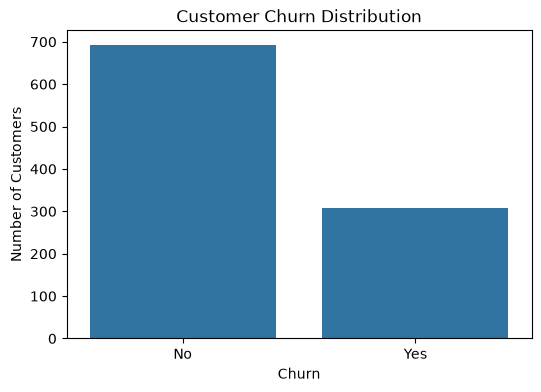

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [13]:
df = df.drop("customerID", axis=1)

In [14]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [15]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
df = df.dropna()

print("New dataset shape:", df.shape)

New dataset shape: (1000, 20)


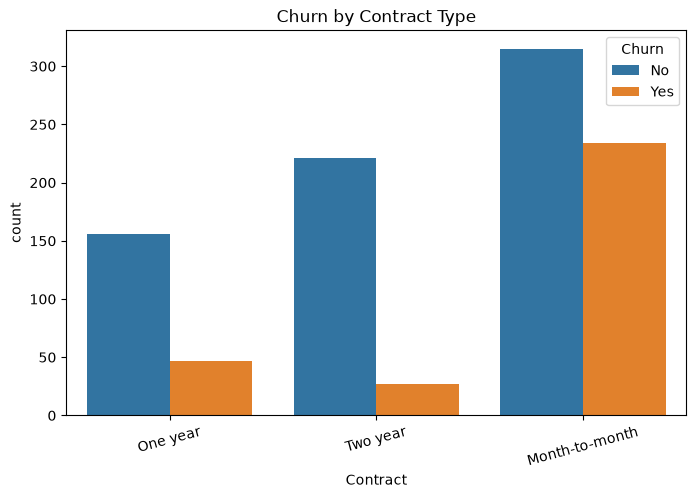

In [17]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract Type")
plt.xticks(rotation=15)

plt.show()

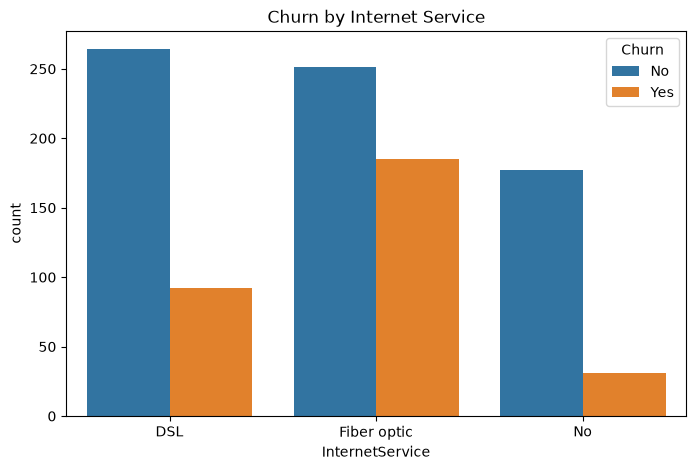

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="InternetService",
    hue="Churn"
)

plt.title("Churn by Internet Service")

plt.show()

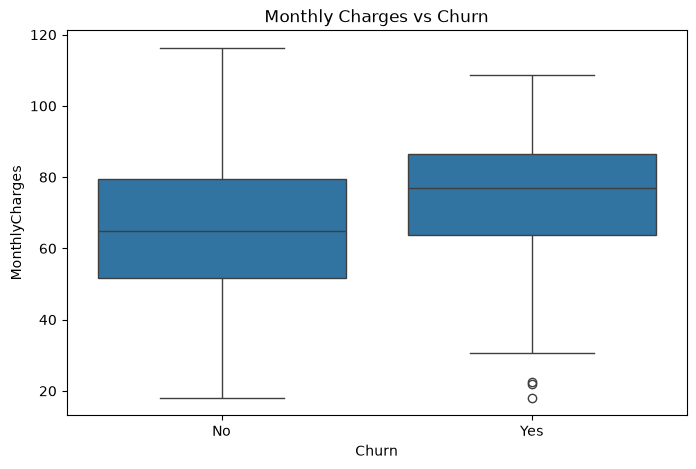

In [19]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Churn")

plt.show()

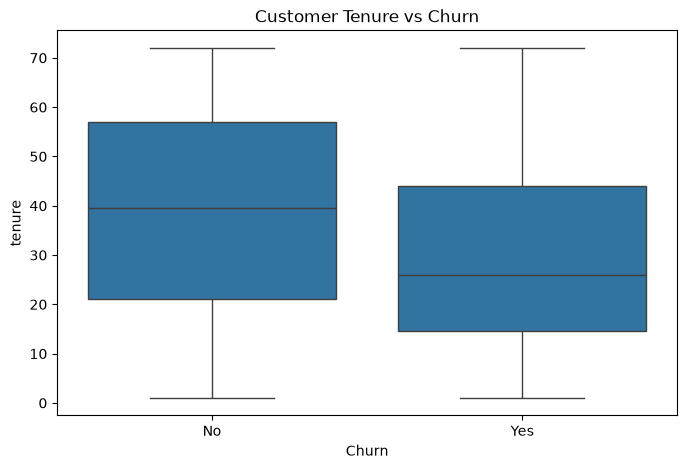

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Customer Tenure vs Churn")

plt.show()

In [21]:
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [22]:
df["Churn"].value_counts()

Churn
0    692
1    308
Name: count, dtype: int64

In [23]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [24]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 19)
y shape: (1000,)


In [25]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical columns:")
print(list(categorical_columns))

print("\nNumerical columns:")
print(list(numerical_columns))

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [27]:
print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (800, 19)
Testing data: (200, 19)


In [28]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

In [29]:
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

In [30]:
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", model)
    ]
)

In [31]:
pipeline.fit(
    X_train,
    y_train
)

print("Model training completed!")

Model training completed!


In [32]:
y_pred = pipeline.predict(
    X_test
)

In [35]:
y_test

67     0
571    0
145    0
270    0
783    0
      ..
199    0
23     0
285    0
329    1
54     0
Name: Churn, Length: 200, dtype: int64

In [36]:
y_pred

array([1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 0])

In [37]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    round(accuracy * 100, 2),
    "%"
)

Accuracy: 70.5 %


In [38]:
precision = precision_score(
    y_test,
    y_pred
)

print(
    "Precision:",
    round(precision, 4)
)

Precision: 0.5224


In [39]:
recall = recall_score(
    y_test,
    y_pred
)

print(
    "Recall:",
    round(recall, 4)
)

Recall: 0.5645


In [40]:
f1 = f1_score(
    y_test,
    y_pred
)

print(
    "F1 Score:",
    round(f1, 4)
)

F1 Score: 0.5426


In [41]:
print("================================")
print("MODEL PERFORMANCE")
print("================================")

print(
    f"Accuracy  : {accuracy:.4f}"
)

print(
    f"Precision : {precision:.4f}"
)

print(
    f"Recall    : {recall:.4f}"
)

print(
    f"F1 Score  : {f1:.4f}"
)

MODEL PERFORMANCE
Accuracy  : 0.7050
Precision : 0.5224
Recall    : 0.5645
F1 Score  : 0.5426


In [42]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.80      0.77      0.78       138
           1       0.52      0.56      0.54        62

    accuracy                           0.70       200
   macro avg       0.66      0.67      0.66       200
weighted avg       0.71      0.70      0.71       200



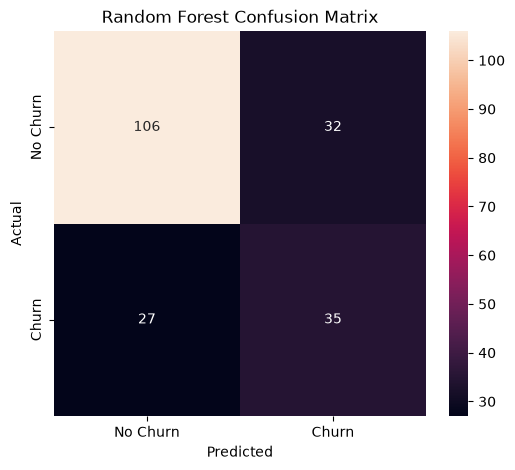

In [43]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "No Churn",
        "Churn"
    ],
    yticklabels=[
        "No Churn",
        "Churn"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

In [44]:
random_forest = pipeline.named_steps["model"]

encoder = pipeline.named_steps[
    "preprocessing"
].named_transformers_["categorical"]

encoded_features = encoder.get_feature_names_out(
    categorical_columns
)

feature_names = np.concatenate([
    encoded_features,
    numerical_columns
])

importance = random_forest.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
43,MonthlyCharges,0.137222
42,tenure,0.122354
44,TotalCharges,0.120285
34,Contract_Two year,0.059754
32,Contract_Month-to-month,0.049365
12,InternetService_Fiber optic,0.023946
40,PaymentMethod_Mailed check,0.018672
2,Partner_No,0.018170
3,Partner_Yes,0.018068
39,PaymentMethod_Electronic check,0.017744


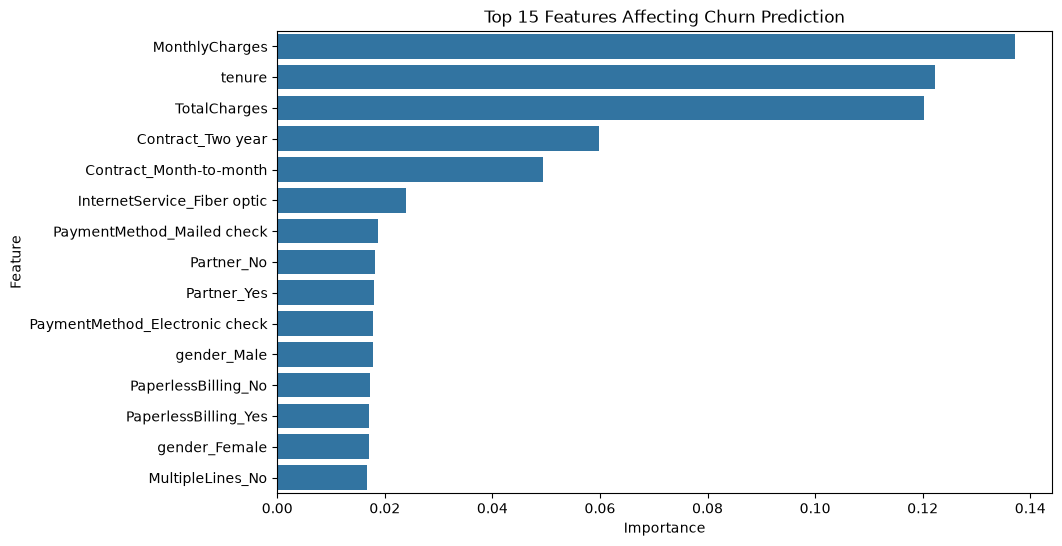

In [45]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Features Affecting Churn Prediction"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [54]:
# predicting the new customer

new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["No"],
    "Dependents": ["No"],
    "tenure": [0.5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["No"],
    "StreamingMovies": ["No"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [10.70],
    "TotalCharges": [2.00]
})

new_prediction = pipeline.predict(
    new_customer
)

new_probability = pipeline.predict_proba(
    new_customer
)[0][1]

print(
    "Churn probability:",
    round(new_probability * 100, 2),
    "%"
)

if new_prediction[0] == 1:
    print("Prediction: Customer is likely to CHURN")
else:
    print("Prediction: Customer is likely to STAY")

Churn probability: 71.16 %
Prediction: Customer is likely to CHURN


In [47]:
!pip install joblib

In [48]:
import joblib

joblib.dump(
    pipeline,
    "telecom_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
